In [1]:
import pandas as pd

df = pd.read_csv("lifecyclesavings.csv")

df.head()

,Contry,sr,pop15,pop75,dpi,ddpi
0,Australia,11.43,29.35,2.87,2329.68,2.87
1,Austria,12.07,23.32,4.41,1507.99,3.93
2,Belgium,13.17,23.80,4.43,2108.47,3.82
3,Bolivia,5.75,41.89,1.67,189.13,0.22
4,Brazil,12.88,42.19,0.83,728.47,4.56


In [2]:
print("Shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nColumn means:")
print(df.mean(numeric_only=True))

Shape: (50, 6)

Missing values:
Contry    0
sr        0
pop15     0
pop75     0
dpi       0
ddpi      0
dtype: int64

Column means:
sr          9.6710
pop15      35.0896
pop75       2.2930
dpi      1106.7584
ddpi        3.7576
dtype: float64


In [3]:
from sklearn.preprocessing import StandardScaler

X = df.select_dtypes(include="number")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data shape:", X_scaled.shape)

Data shape: (50, 5)


In [4]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df["cluster"] = kmeans.fit_predict(X_scaled)

print(df["cluster"].value_counts().sort_index())

cluster
0    18
1     9
2    23
Name: count, dtype: int64


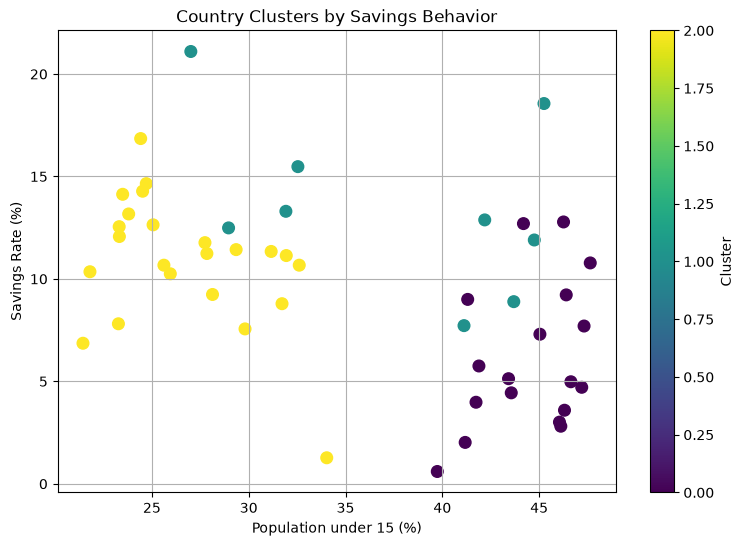

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    df["pop15"],
    df["sr"],
    c=df["cluster"],
    cmap="viridis",
    s=70
)

plt.xlabel("Population under 15 (%)")
plt.ylabel("Savings Rate (%)")
plt.title("Country Clusters by Savings Behavior")
plt.colorbar(scatter, label="Cluster")
plt.grid(True)
plt.show()

In [6]:
# Verify Cluster 0 using groupby

cluster_means = df.groupby("cluster")[X.columns].mean()

print("Cluster 0 means:")
print(cluster_means.loc[0])

print("\nOverall means:")
print(X.mean())

Cluster 0 means:
sr         6.138889
pop15     44.556111
pop75      1.079444
dpi      337.153333
ddpi       2.359444
Name: 0, dtype: float64

Overall means:
sr          9.6710
pop15      35.0896
pop75       2.2930
dpi      1106.7584
ddpi        3.7576
dtype: float64


### My Verification

I used groupby() to check Cluster 0. I found that the average savings rate is 6.14. For all countries, it is 9.67. I also noticed that this group has more children under 15. I think these countries are different from the others.

### My Interpretation

I can see three groups of countries on my chart. Some countries have higher savings rates, and others have lower rates. I think this helps me understand the data better. But I still need to check AI results because AI can make mistakes.

 ### AI Prompt Log

**AI Tool:** ChatGPT

**Prompt 1:** Help me use Python to group countries with similar savings data. I want to use K-Means and understand how it works.

**AI Help:** ChatGPT suggested using StandardScaler to prepare the data and KMeans to create 3 groups.

**Prompt 2:** Help me check how many countries are in each cluster. I want to make sure all 50 countries are included.

**AI Help:** ChatGPT suggested using value_counts(). I got 18, 9, and 23 countries in the three groups.

**Prompt 3:** Help me create a scatter plot to see the clusters. I want to compare savings rates and the population under 15.

**AI Help:** ChatGPT provided Matplotlib code with different colors and labels for each cluster.

**Prompt 4:** Help me check Cluster 0 using groupby(). I want to compare its average values with the averages for all countries.

**AI Help:** ChatGPT suggested using groupby() and mean() to compare the results.

**My Work:** I ran all the code in Jupyter and checked the results. I found that Cluster 0 has a lower average savings rate than the overall data. I also checked the number of countries in each group. The code worked without errors. I wrote my own explanation because I know AI can make mistakes.